# 04 - Five-second sliding-window inference

This notebook applies the saved ensemble to a variable-length audio file. The audio is split into five-second windows with a 2.5-second hop, each window is converted into the same 184 features used during training, and the window probabilities are averaged into one prediction.

The command-line implementation lives in `src/inference.py`. This notebook is for inspecting and experimenting with its outputs.

## 1. Imports and paths

In [6]:
from pathlib import Path
import sys

import librosa
import librosa.display
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.inference import predict_audio

MODEL_PATH = ROOT / 'models' / 'music_detector_pipeline.joblib'
AUDIO_EXTENSIONS = {'.wav', '.mp3', '.flac', '.ogg', '.m4a', '.aiff', '.aif'}
AUDIO_PATH = next(
    (path for path in (ROOT / 'data' / 'raw' / 'ai_generated').iterdir()
     if path.is_file() and path.suffix.lower() in AUDIO_EXTENSIONS),
    None,
)
if not MODEL_PATH.exists():
    raise FileNotFoundError(f'Model not found: {MODEL_PATH}')
if AUDIO_PATH is None:
    raise FileNotFoundError('No audio files found under data/raw/ai_generated.')
print(f'Using audio: {AUDIO_PATH.name}')

Using audio: 000657be-98fe-4f4c-9b00-461ea2079938.mp3


## 2. Choose the window policy

A 2.5-second hop means consecutive five-second windows overlap by 50%. The overlap gives the model more stable coverage around boundaries.

In [7]:
WINDOW_SECONDS = 5.0
HOP_SECONDS = 2.5

result = predict_audio(
    AUDIO_PATH,
    MODEL_PATH,
    window_seconds=WINDOW_SECONDS,
    hop_seconds=HOP_SECONDS,
)

summary = pd.DataFrame([{
    'audio_file': Path(result['audio_path']).name,
    'duration_seconds': result['duration_seconds'],
    'window_seconds': result['window_seconds'],
    'hop_seconds': result['hop_seconds'],
    'window_count': result['window_count'],
    'ai_probability': result['ai_probability'],
    'human_probability': result['human_probability'],
    'predicted_label': result['predicted_label'],
}])
summary

,audio_file,duration_seconds,window_seconds,hop_seconds,window_count,ai_probability,human_probability,predicted_label
0,000657be-98fe-4f4c-9b00-461ea2079938.mp3,167.48,5.0,2.5,66,0.428398,0.571602,human


## 3. Inspect every window

The aggregate probability is the mean of the per-window AI probabilities. Sorting or filtering this table helps identify sections where the model is less confident.

In [8]:
windows = pd.DataFrame(result['windows'])
windows['predicted_label'] = windows['ai_probability'].ge(0.5).map({True: 'ai_generated', False: 'human'})
windows['confidence'] = windows['ai_probability'].where(
    windows['ai_probability'].ge(0.5),
    1.0 - windows['ai_probability'],
)
windows

,start_seconds,end_seconds,ai_probability,predicted_label,confidence
0,0.00,5.00,0.598028,ai_generated,0.598028
1,2.50,7.50,0.498007,human,0.501993
2,5.00,10.00,0.544042,ai_generated,0.544042
3,7.50,12.50,0.591782,ai_generated,0.591782
4,10.00,15.00,0.500053,ai_generated,0.500053
...,...,...,...,...,...
61,152.50,157.50,0.108871,human,0.891129
62,155.00,160.00,0.111631,human,0.888369
63,157.50,162.50,0.053530,human,0.946470
64,160.00,165.00,0.088179,human,0.911821


## 4. Plot the waveform and window predictions

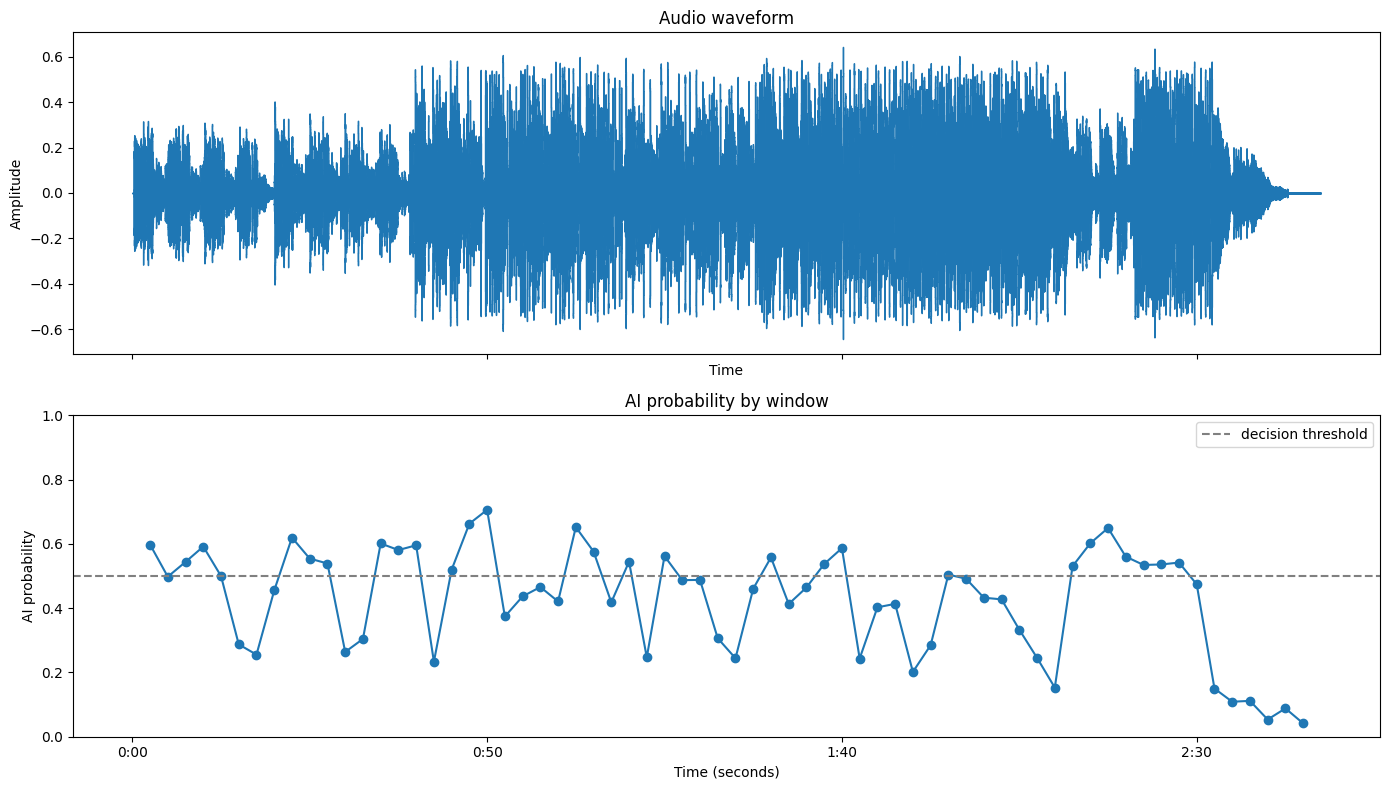

In [9]:
audio, sample_rate = librosa.load(AUDIO_PATH, sr=22050, mono=True)
fig, (waveform_axis, probability_axis) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
librosa.display.waveshow(audio, sr=sample_rate, ax=waveform_axis)
waveform_axis.set_title('Audio waveform')
waveform_axis.set_ylabel('Amplitude')

centers = (windows['start_seconds'] + windows['end_seconds']) / 2
probability_axis.plot(centers, windows['ai_probability'], marker='o')
probability_axis.axhline(0.5, color='gray', linestyle='--', label='decision threshold')
probability_axis.set_title('AI probability by window')
probability_axis.set_xlabel('Time (seconds)')
probability_axis.set_ylabel('AI probability')
probability_axis.set_ylim(0, 1)
probability_axis.legend()
plt.tight_layout()

## 5. Try another local file

Replace `AUDIO_PATH` with any local WAV/MP3 file and rerun the prediction cells. Audio shorter than five seconds is padded with zeros so it still produces one window.